# Pendulum experiments: damping, driving, and nearby trajectories

**Course Assignments / Quizzes | Mathematical Methods for Physicists II**

We start with a simple pendulum, add damping and a periodic drive, then compare nearby initial angles. 

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import math

## Equation and numerical step

For angular position $\theta$ and angular velocity $\omega$,

$$\frac{d\theta}{dt}=\omega,\qquad \frac{d\omega}{dt}=-\frac{g}{L}\sin\theta-q\omega+F_D\sin(\Omega_D t).$$

In [12]:
def pendulum(g, L, q, force, freq, theta0, dt, total_time, wrap=False):
    # Angles are in radians; all experiments start at rest.
    theta = theta0
    omega = 0.0
    times = [0.0]
    angles = [theta]
    speeds = [omega]
    steps = int(round(total_time/dt))

    for i in range(steps):
        t = i*dt
        # Restoring gravity, damping, and drive are all evaluated at the OLD state/time.
        acceleration = -(g/L)*np.sin(theta) - q*omega + force*np.sin(freq*t)
        # Euler–Cromer: update omega first, then use this NEW omega for theta.
        omega = omega + acceleration*dt
        theta = theta + omega*dt
        # Wrapping changes the angle representation, not the physical orientation.
        if wrap:
            theta = (theta + np.pi) % (2*np.pi) - np.pi
        # Retain the entire history, including t=0, for plots and diagnostics.
        times.append((i+1)*dt)
        angles.append(theta)
        speeds.append(omega)
    return times, angles, speeds


## 1. Simple pendulum for practice

**Case:** $g=9.8$, $L=1$, $\theta(0)=0.2$, $\omega(0)=0$, $h=0.02$, $t=10$. 
Plot the angular displacement and velocity, then the phase portrait.


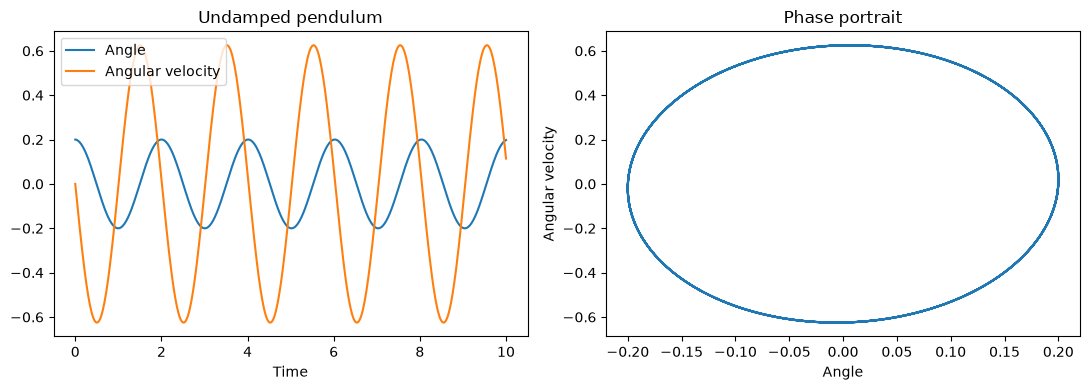

In [13]:
t, theta, omega = pendulum(9.8, 1, 0, 0, 0, 0.2, 0.02, 10)
plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(t, theta, label='Angle')
plt.plot(t, omega, label='Angular velocity')
plt.xlabel('Time')
plt.legend()
plt.title('Undamped pendulum')
plt.subplot(1, 2, 2)
plt.plot(theta, omega)
plt.xlabel('Angle')
plt.ylabel('Angular velocity')
plt.title('Phase portrait')
plt.tight_layout()
plt.show()


## 2. Add damping: Reproducing Fig. 3.4

**Cases:** Keep $g=9.8$, $L=1$, initial angle $0.2$, $h=0.02$, and $t=10$; compare $q=1,5,10$. Include both $\theta(t)$ and the phase portrait for each case. Larger $q$ is stronger damping, although a large $q$ may suppress oscillations rather than simply making them decay faster.

In the small-angle approximation, critical damping occurs at $q_c=2\sqrt{g/L}\approx6.26$ $\rm s^{-1}$ . Thus $q=1,5$ are underdamped and $q=10$ is overdamped. Strong overdamping can make the final return to equilibrium slower.

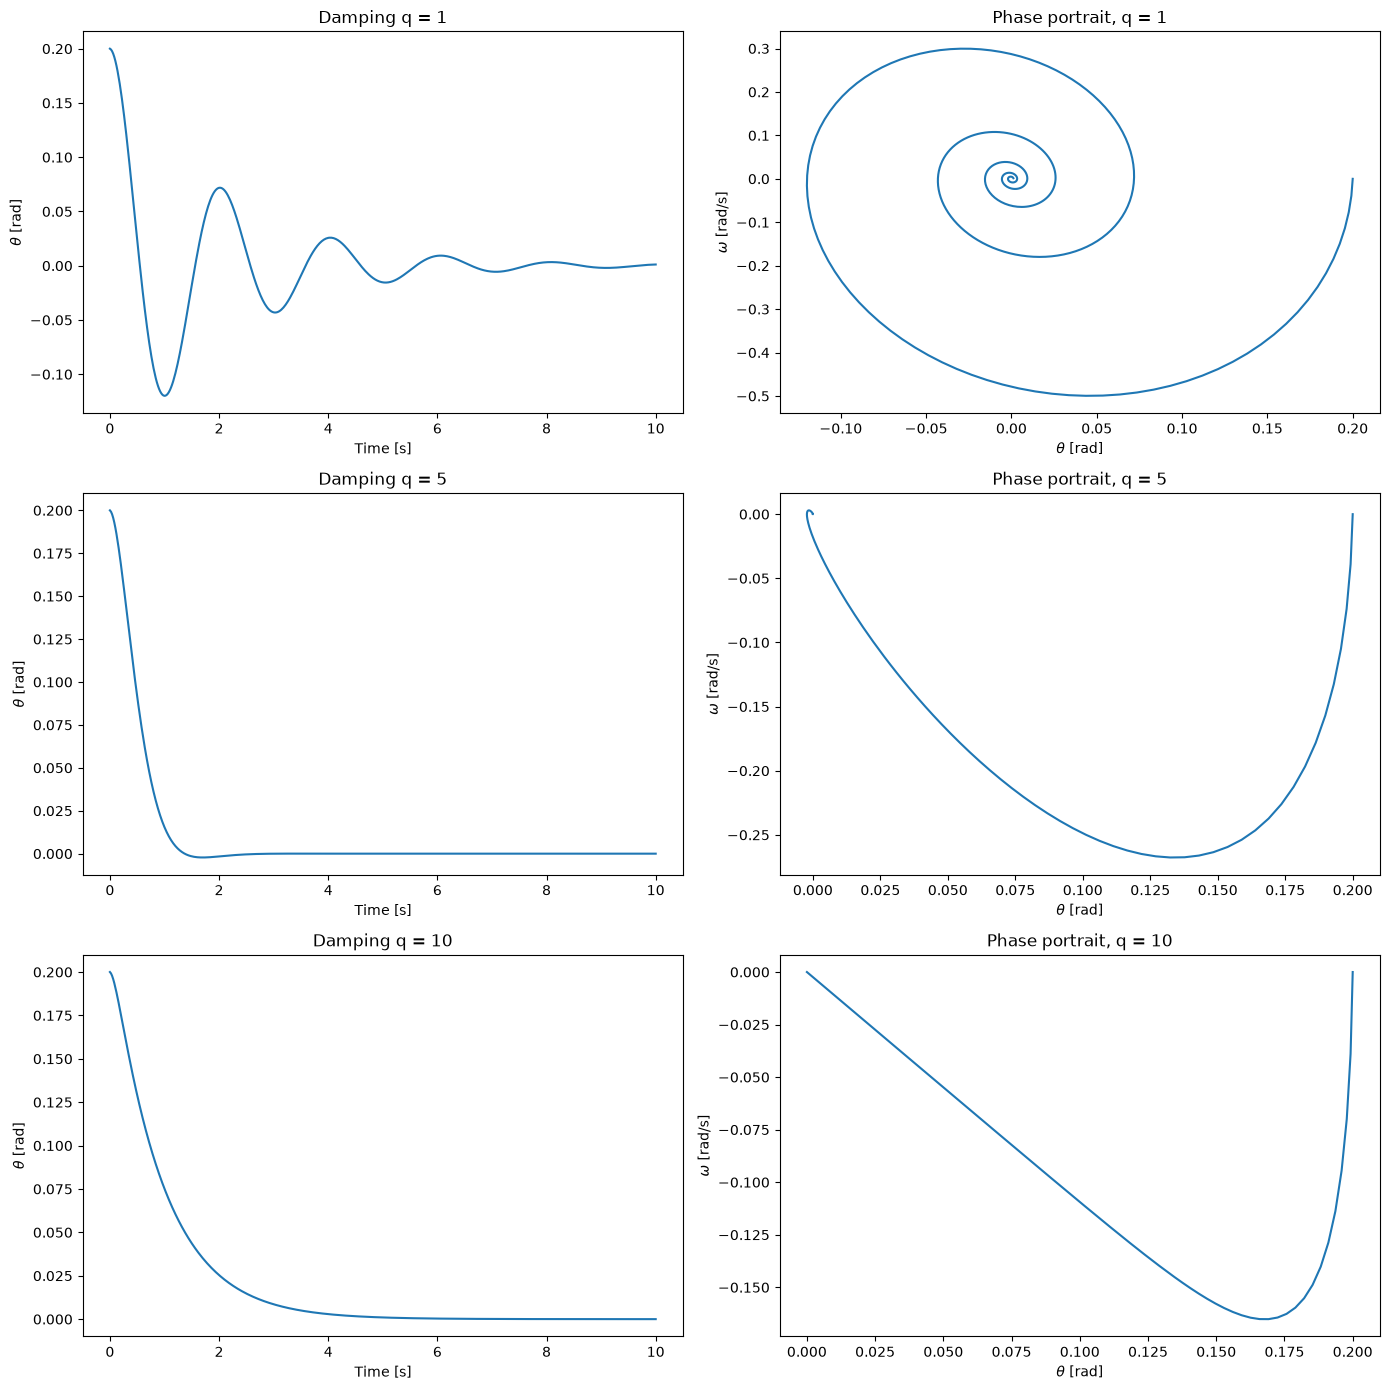

In [14]:
plt.figure(figsize=(14, 14))

# Keep initial state, duration, and step size fixed while changing damping.
for row, q in enumerate([1, 5, 10]):
    t, theta, omega = pendulum(9.8, 1, q, 0, 0, 0.2, 0.02, 10)
    plt.subplot(3, 2, 2*row+1)
    plt.plot(t, theta)
    plt.ylabel('$\\theta$ [rad]')
    plt.xlabel('Time [s]')
    plt.title('Damping q = ' + str(q))
    plt.subplot(3, 2, 2*row+2)
    plt.plot(theta, omega)
    plt.xlabel('$\\theta$ [rad]')
    plt.ylabel('$\\omega$ [rad/s]')
    plt.title('Phase portrait, q = ' + str(q))

plt.tight_layout()
plt.show()


## 3. Driving and large initial angles: Reproducing Fig. 3.5

**Cases:** With $g=9.8$, $L=1$, $h=0.02$, $t=10$, examine $(q,\theta_0,F_D,\Omega_D)=(1,0.2,0.2,2),(0,2.5,0,2),(0,1.5,0,2)$.


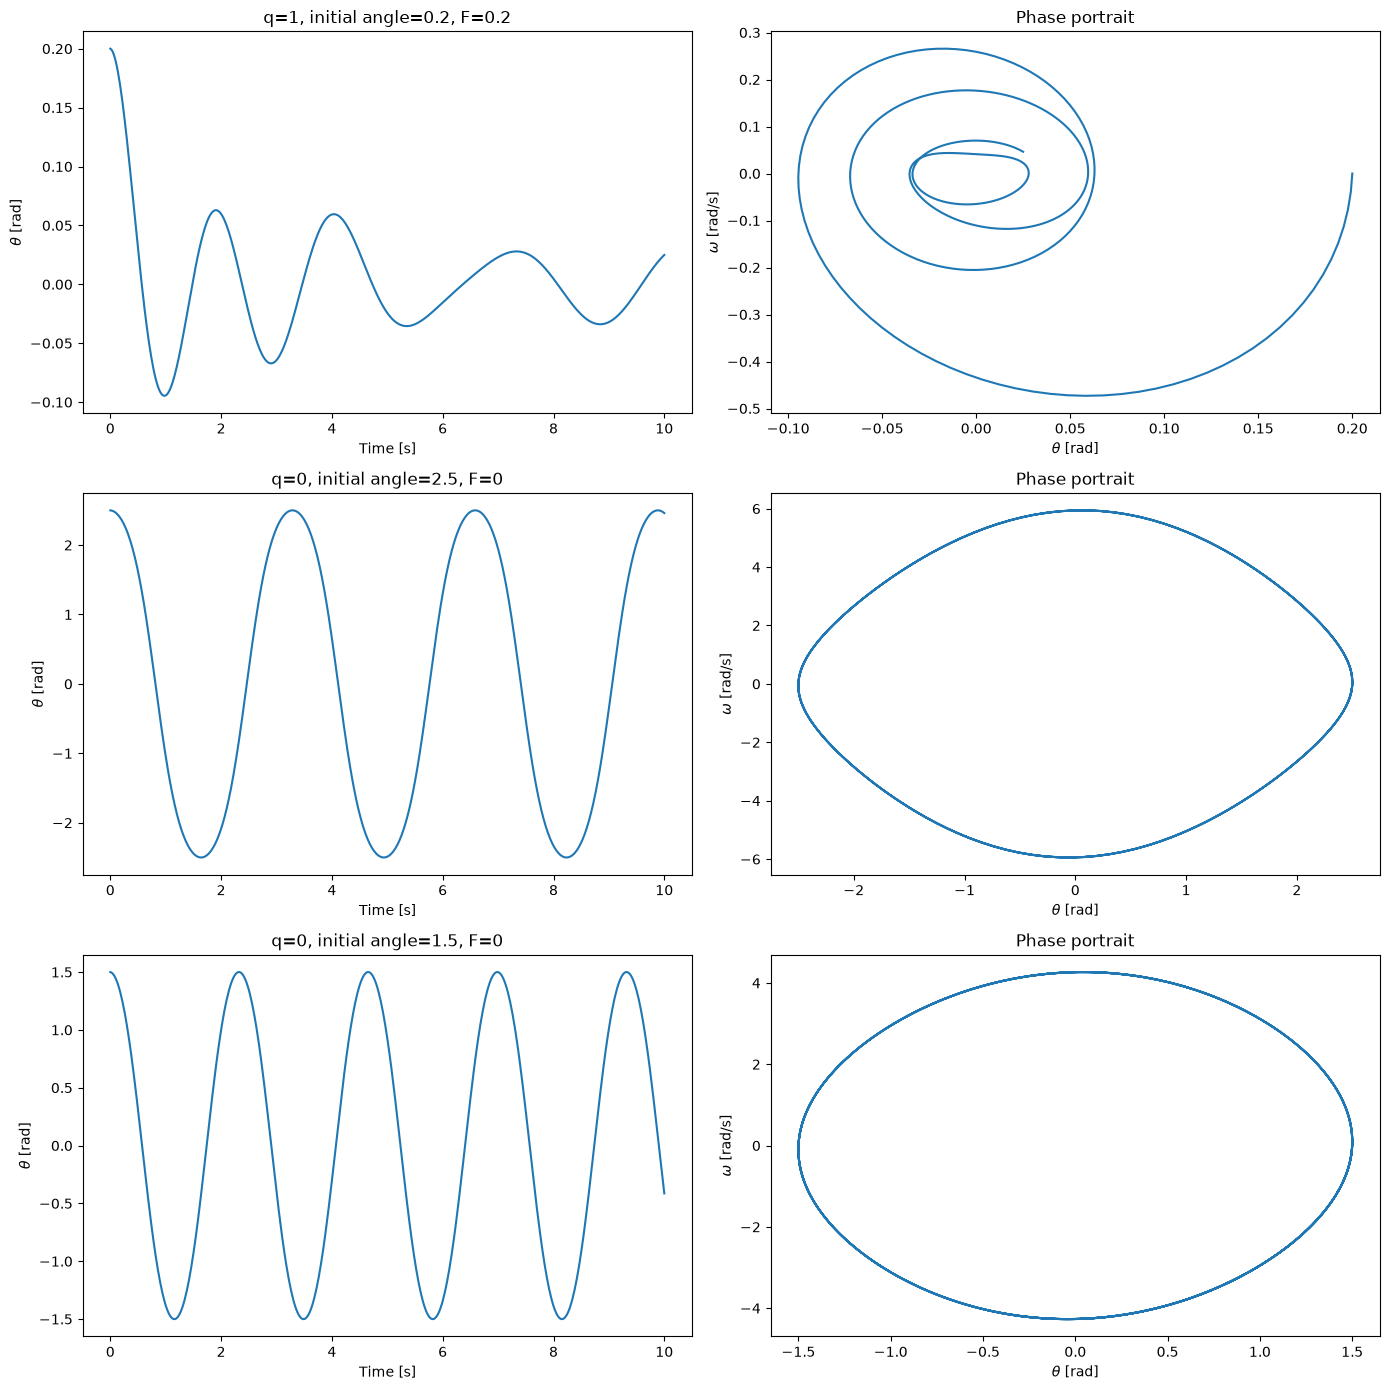

In [15]:
# When force=0, freq has no effect; large initial angles test nonlinear motion.
cases = [(1, 0.2, 0.2, 2), (0, 2.5, 0, 2), (0, 1.5, 0, 2)]

plt.figure(figsize=(14, 14))

for row, (q, angle0, force, freq) in enumerate(cases):
    t, theta, omega = pendulum(9.8, 1, q, force, freq, angle0, 0.02, 10)
    plt.subplot(3, 2, 2*row+1)
    plt.plot(t, theta)
    plt.xlabel('Time [s]')
    plt.ylabel('$\\theta$ [rad]')
    plt.title('q=' + str(q) + ', initial angle=' + str(angle0) + ', F=' + str(force))
    plt.subplot(3, 2, 2*row+2)
    plt.plot(theta, omega)
    plt.xlabel('$\\theta$ [rad]')
    plt.ylabel('$\\omega$ [rad/s]')
    plt.title('Phase portrait')

plt.tight_layout()
plt.show()


## 4. Vary the drive: Reproducing Fig. 3.6

**Cases:** Use $g=L=9.8$ (so $g/L=1$), $q=0.5$, $\Omega_D=2/3$, initial angle $0.2$, $h=0.04$, and $t=60$. Plot angle and angular velocity for $F_D=0,0.5,1.2$.


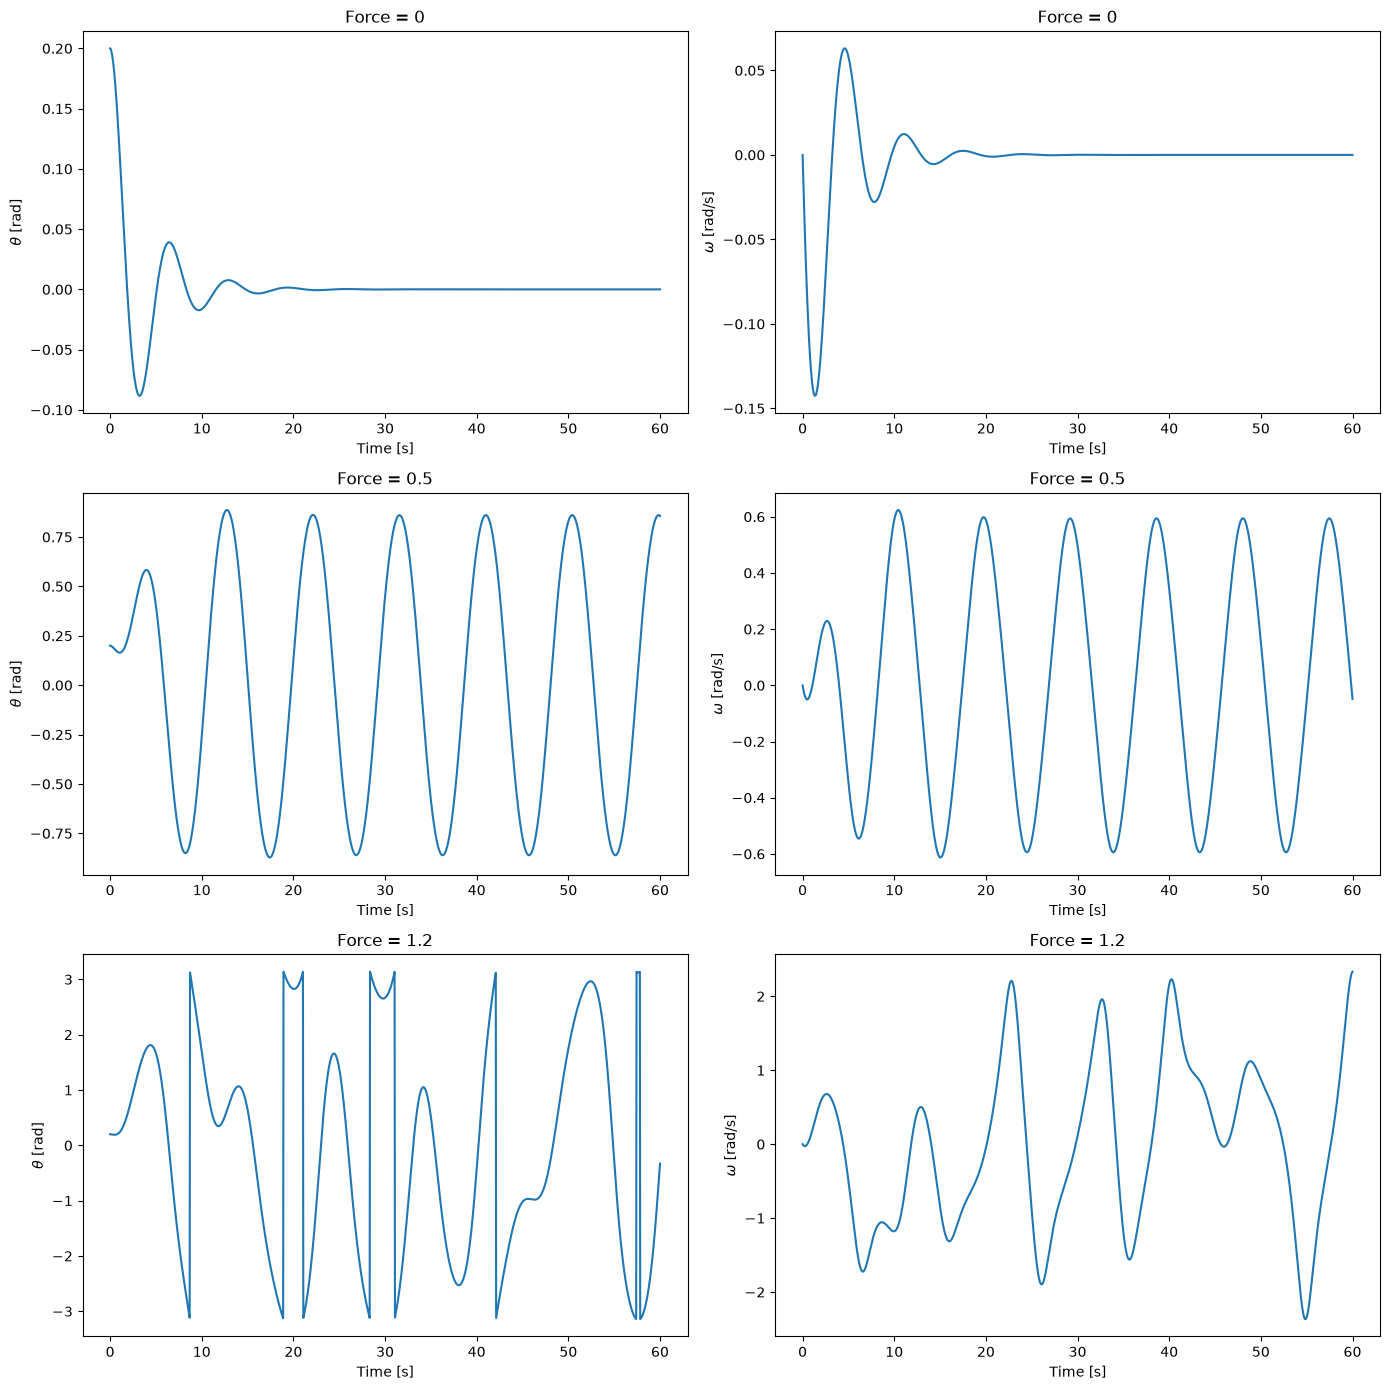

In [16]:
# Wrapped angle jumps at +/-pi are coordinate jumps, not sudden physical motion.
plt.figure(figsize=(14, 14))

for row, force in enumerate([0, 0.5, 1.2]):
    t, theta, omega = pendulum(9.8, 9.8, 0.5, force, 2/3, 0.2, 0.04, 60, wrap=True)
    plt.subplot(3, 2, 2*row+1)
    plt.plot(t, theta)
    plt.xlabel('Time [s]')
    plt.ylabel('$\\theta$ [rad]')
    plt.title('Force = ' + str(force))
    plt.subplot(3, 2, 2*row+2)
    plt.plot(t, omega)
    plt.xlabel('Time [s]')
    plt.ylabel('$\\omega$ [rad/s]')
    plt.title('Force = ' + str(force))

plt.tight_layout()
plt.show()


## 5. Two nearby starting angles: Reproducig Figs. 3.7–3.8

**Cases:** Compare $\theta_0=0.200$ and $0.199$, each starting at rest. Use $q=0.5$, $\Omega_D=2/3$, $h=0.04$, $g=L=9.8$: run $F_D=0.5$ to $t=50$ and $F_D=1.2$ to $t=150$. Preserve both views and also calculate the shortest angular separation so that a crossing of the $\pm\pi$ boundary does not look like a large physical separation.


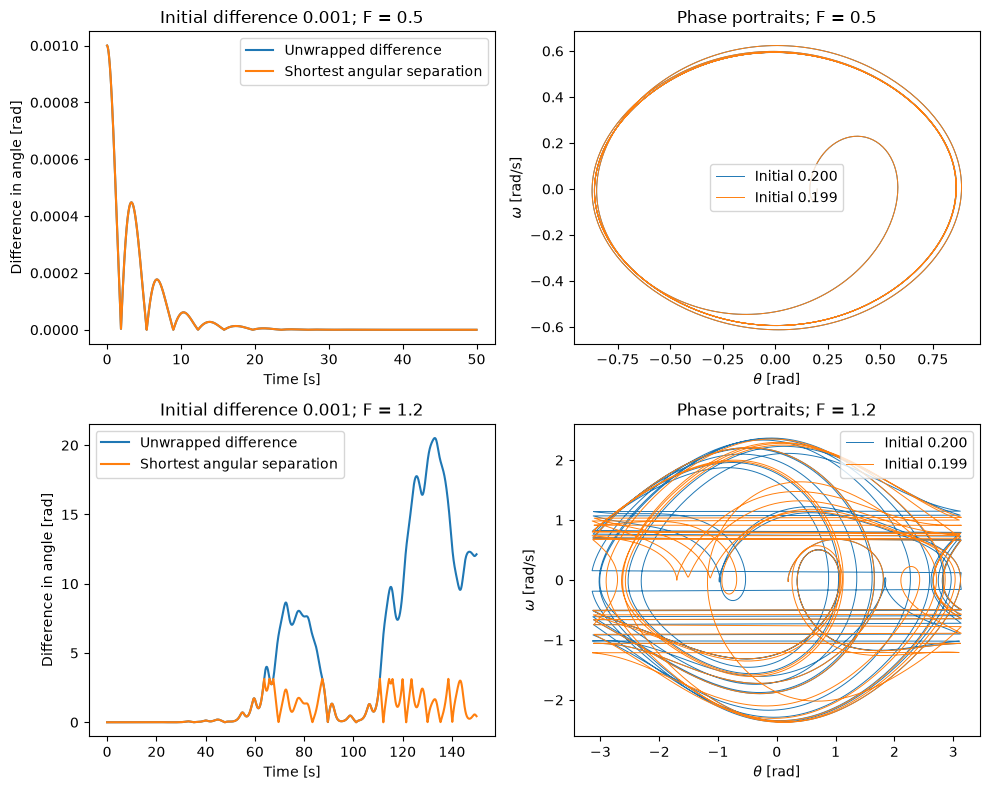

In [17]:
def angle_separation(a, b):
    # Map the difference into [-pi, pi), then take its magnitude.
    return abs((a-b+np.pi) % (2*np.pi) - np.pi)

plt.figure(figsize=(10, 8))

for row, (force, final_time) in enumerate([(0.5, 50), (1.2, 150)]):
    t, theta_a, omega_a = pendulum(9.8, 9.8, 0.5, force, 2/3, 0.200, 0.04, final_time)
    t, theta_b, omega_b = pendulum(9.8, 9.8, 0.5, force, 2/3, 0.199, 0.04, final_time)
    
    # Integrate unwrapped so full rotations are not lost; wrap only for orientation plots.
    raw_difference = []
    angular_difference = []
    
    for i in range(len(t)):
        raw_difference.append(abs(theta_a[i]-theta_b[i]))
        angular_difference.append(angle_separation(theta_a[i], theta_b[i]))

    plt.subplot(2, 2, 2*row+1)
    plt.plot(t, raw_difference, label='Unwrapped difference')
    plt.plot(t, angular_difference, label='Shortest angular separation')
    plt.xlabel('Time [s]')
    plt.ylabel('Difference in angle [rad]')
    plt.title('Initial difference 0.001; F = ' + str(force))
    plt.legend()

    plt.subplot(2, 2, 2*row+2)
    wrapped_a = [(angle+np.pi) % (2*np.pi)-np.pi for angle in theta_a]
    wrapped_b = [(angle+np.pi) % (2*np.pi)-np.pi for angle in theta_b]
    plt.plot(wrapped_a, omega_a, linewidth=0.7, label='Initial 0.200')
    plt.plot(wrapped_b, omega_b, linewidth=0.7, label='Initial 0.199')
    plt.xlabel('$\\theta$ [rad]')
    plt.ylabel('$\\omega$ [rad/s]')
    plt.title('Phase portraits; F = ' + str(force))
    plt.legend()

plt.tight_layout()
plt.show()


### How to read these plots

Each **row** compares two pendulums that start almost identically: one at
$\theta_0=0.200$ and the other at $\theta_0=0.199$, both at rest. The top row
uses $F_D=0.5$; the bottom row uses $F_D=1.2$.

The **left panel** shows how their angular positions differ over time. It has
two lines because an angle difference can be measured in two useful ways:

- **Unwrapped difference**, $|\theta_A-\theta_B|$, retains accumulated full
  rotations. It can become large if one pendulum completes more turns than
  the other.
- **Shortest angular separation** measures the distance between their
  *current orientations*, treating angles that differ by $2\pi$ as equivalent.
  For example, $179^\circ$ and $-179^\circ$ are only $2^\circ$ apart in
  orientation.

The **right panel** overlays the two trajectories in phase space: angular
position on the horizontal axis and angular velocity on the vertical axis.
This shows whether the pendulums follow similar patterns of motion, beyond
their angular separation at any one instant.

A large unwrapped difference does not always mean their current orientations
are far apart: one pendulum may simply have completed an extra turn. Conversely,
a small shortest angular separation does not mean their full motions are
identical; their angular velocities may differ.

## 6. Compare integration methods on the undamped pendulum *(later addition)*

This comparison adds midpoint RK2 and classical RK4 for the **same** undamped pendulum, $g/L=1$, $\theta(0)=0.2$, $h=0.1$, $t=80$. Its conserved energy per unit mass is $E=\omega^2/2+(g/L)(1-\cos\theta)$. The aim is to inspect numerical energy behavior.

Reduced energy has units $\rm s^{-2}$. Multiply by $mL^2$ to obtain joules, or by $L^2$ to obtain energy per unit mass. Energy conservation is a diagnostic for this undamped, undriven case only.



semi-implicit Euler maximum absolute energy change: 0.0010462
RK2 maximum absolute energy change: 0.0003972
RK4 maximum absolute energy change: 2e-07


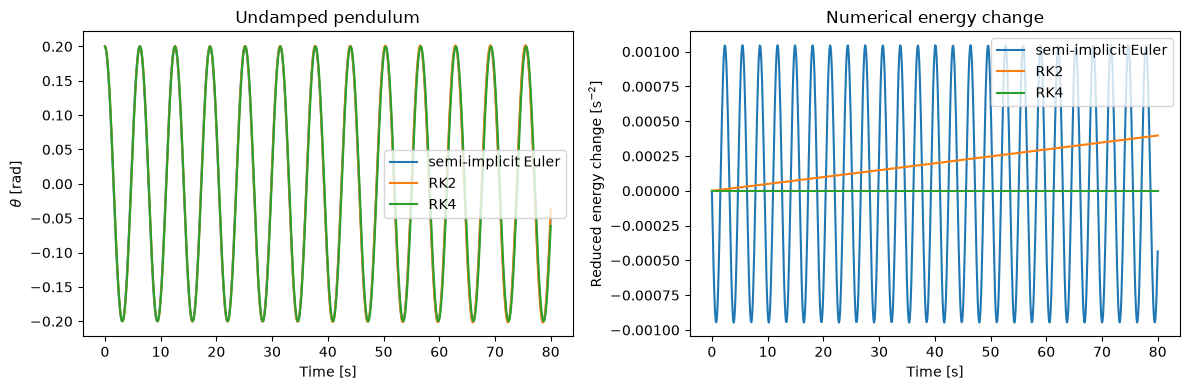

In [18]:
def pendulum_other_method(method, h, steps, g_over_L=1, angle0=0.2):
    theta, omega = angle0, 0.0
    times, angles, speeds = [0], [theta], [omega]
    
    for i in range(steps):
        
        # Midpoint RK2 uses the predicted midpoint angle AND velocity.
        if method == 'RK2':
            middle_theta = theta + h*omega/2
            middle_omega = omega - h*g_over_L*np.sin(theta)/2
            next_theta = theta + h*middle_omega
            next_omega = omega - h*g_over_L*np.sin(middle_theta)
        
        # RK4 combines four coupled-state slope estimates with weights 1,2,2,1.
        elif method == 'RK4':
            k1theta, k1omega = omega, -g_over_L*np.sin(theta)
            k2theta = omega + h*k1omega/2
            k2omega = -g_over_L*np.sin(theta + h*k1theta/2)
            k3theta = omega + h*k2omega/2
            k3omega = -g_over_L*np.sin(theta + h*k2theta/2)
            k4theta = omega + h*k3omega
            k4omega = -g_over_L*np.sin(theta + h*k3theta)
            next_theta = theta + h*(k1theta + 2*k2theta + 2*k3theta + k4theta)/6
            next_omega = omega + h*(k1omega + 2*k2omega + 2*k3omega + k4omega)/6
        
        else:
            raise ValueError('Choose RK2 or RK4')
        
        theta, omega = next_theta, next_omega
        times.append((i+1)*h)
        angles.append(theta)
        speeds.append(omega)
    
    return times, angles, speeds

h, steps = 0.1, 800

plt.figure(figsize=(12, 4))

for method in ['semi-implicit Euler', 'RK2', 'RK4']:
    if method == 'semi-implicit Euler':
        t, theta, omega = pendulum(1, 1, 0, 0, 0, 0.2, h, h*steps)
    else:
        t, theta, omega = pendulum_other_method(method, h, steps)
    
    energy = []
    
    for i in range(len(t)):
        # Reduced energy E/(m*L**2), with g/L=1 in this comparison.
        energy.append(omega[i]**2/2 + 1 - np.cos(theta[i]))
    
    plt.subplot(1, 2, 1)
    plt.plot(t, theta, label=method)
    plt.subplot(1, 2, 2)
    plt.plot(t, np.array(energy)-energy[0], label=method)
    print(method, 'maximum absolute energy change:', round(max(abs(np.array(energy)-energy[0])), 7))

plt.subplot(1, 2, 1)
plt.xlabel('Time [s]')
plt.ylabel('$\\theta$ [rad]')
plt.title('Undamped pendulum')
plt.legend()
plt.subplot(1, 2, 2)
plt.xlabel('Time [s]')
plt.ylabel('Reduced energy change [s$^{-2}$]')
plt.title('Numerical energy change')
plt.legend()
plt.tight_layout()
plt.show()


All three methods solve the same undamped, undriven pendulum with the same initial conditions, step size, and duration. Differences between their results therefore arise from numerical integration.

- **Angle versus time:** The curves can appear nearly identical while still having small amplitude or phase errors. Agreement in this plot alone does not establish equal accuracy.
- **Reduced-energy change:** The exact pendulum conserves energy, so the exact value of the plotted change is zero. Any departure from zero is numerical error.

Euler–Cromer typically produces an oscillating energy error that remains bounded for a sufficiently small step. Midpoint RK2 can accumulate energy drift despite being more accurate over short intervals. RK4 gives a much smaller energy error for this particular step size and duration.

The plotted quantity is **reduced energy**,  
$$
\mathcal{E}=\frac{E_{\mathrm{physical}}}{mL^2}
=\frac{\omega^2}{2}+\frac{g}{L}(1-\cos\theta),
$$
with units of $\mathrm{s}^{-2}$. It is not energy in joules.

A small energy error does not guarantee the correct oscillation period: a method can preserve energy approximately while accumulating phase error. Both plots should therefore be considered together. This comparison describes the chosen experiment; it does not establish one method as best for every problem.

## 7. Step-size checks and a Poincaré section (extension)

For the nearby-angle experiment, repeat the separation calculation at $h=0.04,0.02,0.01$. Chaotic trajectories can cease agreeing point by point even when each simulation is accurate; inspect early separation and qualitative behaviour, rather than requiring agreement forever. This is not a Lyapunov-exponent measurement.

A Poincaré section records $(\theta,\omega)$ once per drive period $T_D=2\pi/\Omega_D$ at the **same driving phase**. Discard the first 100 periods and plot the next 300. Use steps that divide each drive period exactly, avoiding interpolation and phase drift. A periodic attractor gives one or a few points; a distributed set can support a chaotic interpretation, but is not proof by itself. Check that its overall appearance persists under refinement. The long-run state can also depend on the initial condition and attractor basin.


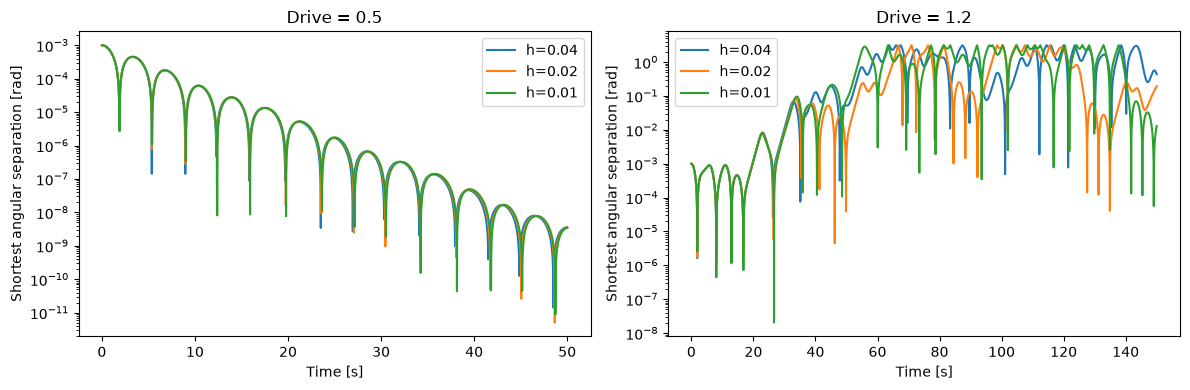

In [20]:
# Repeat the original sensitivity experiment with smaller steps.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (drive, duration) in zip(axes, [(0.5, 50), (1.2, 150)]):
    for h in [0.04, 0.02, 0.01]:
        t, a, _ = pendulum(9.8, 9.8, 0.5, drive, 2/3, 0.200, h, duration)
        _, b, _ = pendulum(9.8, 9.8, 0.5, drive, 2/3, 0.199, h, duration)
        separation = angle_separation(np.asarray(a), np.asarray(b))
        ax.semilogy(t, np.maximum(separation, 1e-15), label=f'h={h}')
    
    ax.set(xlabel='Time [s]', ylabel='Shortest angular separation [rad]', title=f'Drive = {drive}')
    ax.legend()

plt.tight_layout()
plt.show()



Each panel repeats the nearby-initial-angle experiment at three step sizes while keeping the physical parameters, initial angles, and duration fixed. This checks whether the observed sensitivity depends strongly on numerical resolution.

For the weaker drive, the nearby trajectories tend toward the same periodic response, and their angular separation generally decreases. For the stronger drive, their separation grows and fluctuates, supporting sensitive dependence on the initial state.

The detailed separation curves need not coincide indefinitely across step sizes. In chaotic motion, small numerical errors are amplified alongside the deliberate initial-angle difference. Refinement can improve the interval of reliable trajectory prediction without producing identical long-time trajectories.

The logarithmic vertical axis makes small separations visible. However:

- The plotted distance measures **orientation difference only**; angular velocities may differ even when the angles nearly coincide.
- Shortest angular separation is bounded by $\pi$, so its growth eventually saturates or fluctuates.
- The floor of $10^{-15}$ prevents plotting the logarithm of zero; it is a display choice.
- A rising segment is not, by itself, a measurement of a Lyapunov exponent.

These plots provide a qualitative sensitivity check. They should be interpreted together with the Poincaré sections rather than treated as a standalone proof of chaos.

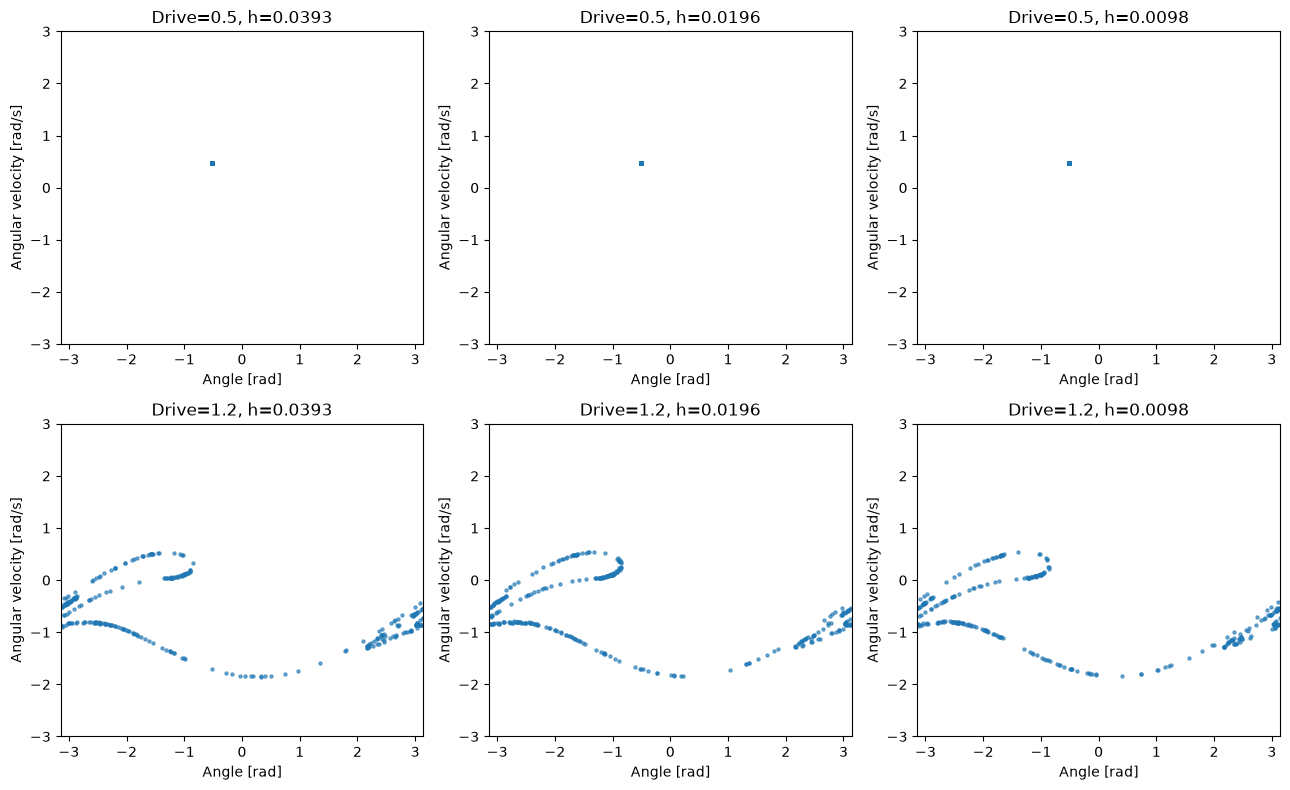

In [21]:
# Sample at t=n*T_drive, always at drive phase zero.
drive_period = 2*np.pi/(2/3)
discard_periods, retained_periods = 100, 300
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
poincare_samples = {}

for row, drive in enumerate([0.5, 1.2]):
    for col, steps_per_period in enumerate([240, 480, 960]):
        h = drive_period/steps_per_period
        duration = (discard_periods+retained_periods)*drive_period
        t, theta, omega = pendulum(9.8, 9.8, 0.5, drive, 2/3, 0.2, h, duration)
        # Integer indices enforce the same phase, with exactly 300 retained samples.
        indices = np.arange(discard_periods+1, discard_periods+retained_periods+1)*steps_per_period
        sample_theta = (np.asarray(theta)[indices]+np.pi) % (2*np.pi)-np.pi
        sample_omega = np.asarray(omega)[indices]
        poincare_samples[(drive, steps_per_period)] = (sample_theta, sample_omega)
        ax = axes[row, col]
        ax.scatter(sample_theta, sample_omega, s=5, alpha=0.6)
        ax.set(xlabel='Angle [rad]', ylabel='Angular velocity [rad/s]',
               title=f'Drive={drive}, h={h:.4f}', xlim=(-np.pi, np.pi), ylim=(-3, 3))

plt.tight_layout()
plt.show()

Each point records the pendulum’s angle and angular velocity once per driving period, always at the same driving phase. This removes the overlapping motion from different phases of the drive and makes recurring behaviour easier to identify.

The first 100 driving periods are discarded to reduce the initial transient, and the following 300 periods supply the plotted points. The three columns use progressively smaller steps, chosen to divide each driving period exactly.

- **Drive strength 0.5:** The samples form a compact, point-like pattern at all three resolutions. This is consistent with a response that repeats once per driving period after the transient.
- **Drive strength 1.2:** The samples form a structured, distributed set. Its overall appearance persists under refinement, supporting the interpretation of a chaotic attractor for this initial condition.

Individual points in the stronger-drive plots need not match across resolutions: the trajectories can diverge long before sampling begins. The useful comparison is whether the overall organisation of the sampled set persists.

A distributed set alone does not prove chaos. Residual transients, quasiperiodicity, a high-period orbit, or numerical errors can also produce many distinct points. Longer runs, additional refinement, and a converged Lyapunov-exponent calculation would strengthen the conclusion.

These sections describe motion starting at $\theta_0=0.2$ with zero angular velocity. Other initial states may approach different attractors. Wrapping the sampled angle identifies equivalent orientations but does not retain the number of complete revolutions.

**Reference:** Nicholas J. Giordano and Hisao Nakanishi, *Computational Physics* (Addison-Wesley, 2005), Chapter 3. The figure numbers 3.4–3.8 are transcribed from my original *Homework 05* labels. This notebook is an exercise-based reconstruction.

## Equations used in this Notebook

### Pendulum: free, damped, and driven

The pendulum exercises use
$$
\frac{d\theta}{dt}=\omega,
$$
$$
\frac{d\omega}{dt}
=-\frac{g}{L}\sin\theta-q\omega+F_D\sin(\Omega_Dt).
$$

Here $\theta$ is the angle, $\omega$ is its angular velocity, $q$ controls damping, and $F_D$ and $\Omega_D$ set the strength and frequency of the external drive. Setting $q=0$ removes damping; setting $F_D=0$ removes the drive.

The original pendulum code uses **semi-implicit Euler**: it updates angular velocity first and then uses that new value to update the angle,
$$
\omega_{n+1}=\omega_n+h\left[-\frac{g}{L}\sin\theta_n-q\omega_n
+F_D\sin(\Omega_Dt_n)\right],
$$
$$
\theta_{n+1}=\theta_n+h\omega_{n+1}.
$$

For the undamped, undriven pendulum, energy per unit mass is
$$
E=\frac{\omega^2}{2}+\frac{g}{L}(1-\cos\theta).
$$
It should remain constant in the physical model, making it useful for comparing numerical methods.